In [19]:
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset

In [20]:
ds_train = load_dataset("coastalcph/lex_glue", "unfair_tos", split="train")
ds_val = load_dataset("coastalcph/lex_glue", "unfair_tos", split="validation")
ds_test = load_dataset("coastalcph/lex_glue", "unfair_tos", split="test")

In [21]:
ds_train.to_pandas().to_csv("../../data/raw/train.csv", index=False)
ds_val.to_pandas().to_csv("../../data/raw/val.csv", index=False)
ds_test.to_pandas().to_csv("../../data/raw/test.csv", index=False)

In [22]:
train = pd.read_csv("../../data/raw/train.csv")
val = pd.read_csv("../../data/raw/val.csv")
test = pd.read_csv("../../data/raw/test.csv")

In [23]:
import re

from sklearn.preprocessing import MultiLabelBinarizer


def parse_labels(s):
    return [int(x) for x in re.findall(r"\d+", s)]

for d in (train, val, test):
    d['labels'] = d['labels'].apply(parse_labels)

NAMES = ["Limitation of liability", "Unilateral termination", "Unilateral change", "Content removal", "Contract by using", "Choice of law", "Jurisdiction", "Arbitration"]

mlb = MultiLabelBinarizer(classes=list(range(8)))
Y_train = mlb.fit_transform(train["labels"])
Y_val = mlb.transform(val["labels"])
Y_test = mlb.transform(test["labels"])

In [45]:
Y_train[Y_train.sum(1) != 0][0]

array([0, 0, 0, 0, 1, 0, 0, 0])

In [24]:
audit = pd.DataFrame({
    "Rows": [len(d) for d in (train, val, test)],
    "Empty Text": [(d["text"].fillna("").str.strip() == "").sum() for d in (train, val, test)],
    "Duplicate Text": [d["text"].duplicated().sum() for d in (train, val, test)],
    "Fair Rows": [(d["labels"].apply(len) == 0).sum() for d in (train, val, test)],
    "Unfair Rows": [(d["labels"].apply(len) > 0).sum() for d in (train, val, test)],
}, index=["Train", "Validation", "Test"])
audit

,Rows,Empty Text,Duplicate Text,Fair Rows,Unfair Rows
Train,5532,0,105,4902,630
Validation,2275,0,14,2045,230
Test,1607,0,7,1435,172


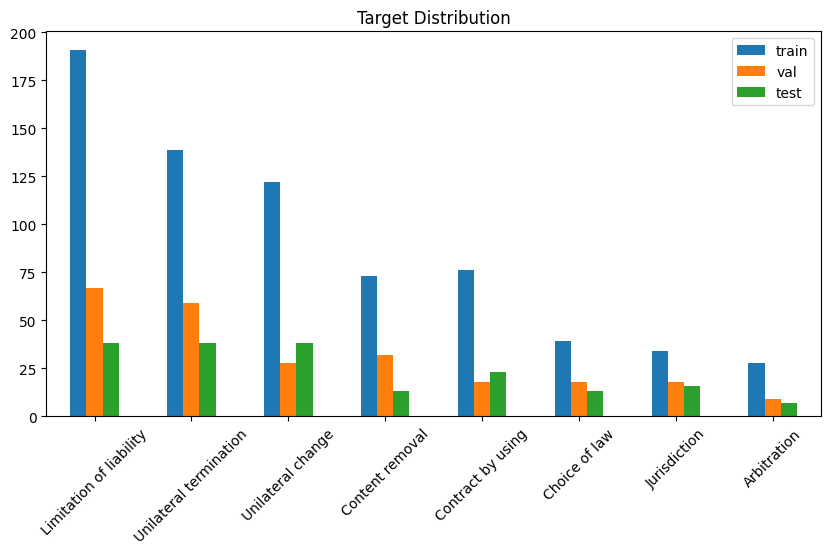

In [46]:
dist = pd.DataFrame({"train": Y_train.sum(0), "val": Y_val.sum(0), "test": Y_test.sum(0)}, index=NAMES)
dist.plot.bar(rot=45, figsize=(10, 5), title="Target Distribution")
plt.show()